# Week 4 — Prepared video data quality

The Week 3 video handoff consists of two frame ZIPs, the frame index CSV, and the pipeline run manifest. These play the roles of inspectable records and reusable prepared data in the handout's text example. Use the project repository as the working directory. In a fresh Colab session, clone the project and change into its root before running these cells.

```python
!git clone https://github.com/yx-le/ai-engineering-fire-smoke-video-evaluation.git
%cd ai-engineering-fire-smoke-video-evaluation
%pip -q install 'pandera[pandas]'
```

## A0 — Plan the quality gate

| Topic 2 requirement | Data need | Quality dimensions | Check and decision |
| --- | --- | --- | --- |
| FR-01 | Trace each frame to a selected clip and its reference label | Completeness, consistency, uniqueness | Confirm clip identity, a populated label, exact archive membership, and unique clip/frame keys. Hold records with broken lineage. |
| FR-02 | Provide timestamped frames suitable for offline processing | Accuracy, consistency, timeliness | Reconcile timestamps with frame indices and source FPS, decode images and compare dimensions, and record which source/run version was audited. Review freshness separately from file integrity. |

The gate covers preparation inputs for FR-02. Detector predictions and performance are outside this audit.

Topic 2 evaluation links: EC-04 guides the clip and source checks. EC-02 calls for marking metrics unavailable when timestamps or labels cannot support them. The Week 3 inventory and pipeline diagram record source access, release and preparation decisions.

In [1]:
# A1 — Verify the Topic 3 handoff
from pathlib import Path
import hashlib
import io
import json
import zipfile
import pandas as pd
from PIL import Image
from IPython.display import display

root = next((base for base in (Path.cwd(), *Path.cwd().parents)
             if (base / 'data/pipeline_v1/video/pipeline_manifest.json').is_file()), None)
if root is None:
    raise FileNotFoundError('Open the notebook inside the Week 3 project checkout.')
folder = root / 'data/pipeline_v1/video'
manifest = json.loads((folder / 'pipeline_manifest.json').read_text(encoding='utf-8'))
verified = []
for record in manifest['outputs']:
    path = root / record['path']
    payload = path.read_bytes()
    if len(payload) != record['bytes'] or hashlib.sha256(payload).hexdigest() != record['sha256']:
        raise ValueError(f'Handoff fingerprint mismatch: {path.name}')
    verified.append(path.name)
if set(verified) != {'evo_10_frames.zip', 'evo_11_frames.zip', 'frame_manifest.csv'}:
    raise ValueError(f'Unexpected output set: {verified}')
print('Verified byte sizes and SHA-256:', ', '.join(verified))
print('Run version and timestamp:', manifest['pipeline_version'], manifest['generated_at_utc'])

frames = pd.read_csv(folder / 'frame_manifest.csv', dtype={'has_smoke': 'string'})
if frames.empty:
    raise ValueError('Frame index is empty')
frames['has_smoke'] = frames['has_smoke'].str.lower()
clips = {row['filename']: row for row in manifest['inspection']['clips']}
print('Frame rows by clip:', frames['source_clip'].value_counts().sort_index().to_dict())

Verified byte sizes and SHA-256: evo_10_frames.zip, evo_11_frames.zip, frame_manifest.csv
Run version and timestamp: week3-v1 2026-11-11T10:24:47.469557+00:00
Frame rows by clip: {'evo_10.mp4': 15, 'evo_11.mp4': 17}


In [2]:
# A2 — Inventory each frame and its archive member
prefix = 'data/pipeline_v1/video/frames/'
archives = {}
archive_names = {}
for path in sorted(folder.glob('evo_*_frames.zip')):
    with zipfile.ZipFile(path) as archive:
        for member in archive.infolist():
            if member.is_dir():
                continue
            key = prefix + member.filename
            if key in archives:
                raise ValueError(f'Duplicate ZIP member: {key}')
            archives[key] = archive.read(member)
            archive_names[key] = path.name

def image_properties(payload):
    if payload is None:
        return None, None
    try:
        with Image.open(io.BytesIO(payload)) as image:
            image.load()
            return image.format, image.size
    except (OSError, ValueError):
        return None, None

frames['member_present'] = frames['prepared_image'].isin(archives)
properties = [image_properties(archives.get(path)) for path in frames['prepared_image']]
frames['image_format'] = [fmt for fmt, _ in properties]
frames['decoded_size'] = [size for _, size in properties]
frames['duplicate_key'] = frames.duplicated(['source_clip', 'source_frame_index'], keep=False)
extra = set(archives) - set(frames['prepared_image'].dropna())
print('Frame index rows:', len(frames), '| Archived images:', len(archives))
print('Missing CSV values:', {col: int(count) for col, count in frames.iloc[:, :11].isna().sum().items() if count})
print('Missing members:', int((~frames['member_present']).sum()))
print('Unreadable members:', int((frames['member_present'] & frames['decoded_size'].isna()).sum()))
print('Unindexed archive members:', sorted(extra))
print('Rows with duplicate clip/frame keys:', int(frames['duplicate_key'].sum()))
print('Clip label distribution:', frames.drop_duplicates('source_clip')['has_smoke'].value_counts().to_dict())
print('Noise review:', 'Decoder checks flag unreadable files. Faint smoke, blur, and compression artefacts require visual review.')
print('Staleness review:', 'N.V. for the current official annotation revision. The audited run timestamp is recorded above.')


Frame index rows: 32 | Archived images: 32
Missing CSV values: {}
Missing members: 0
Unreadable members: 0
Unindexed archive members: []
Rows with duplicate clip/frame keys: 0
Clip label distribution: {'true': 2}
Noise review: Decoder checks flag unreadable files. Faint smoke, blur, and compression artefacts require visual review.
Staleness review: N.V. for the current official annotation revision. The audited run timestamp is recorded above.


evo_10.mp4 | 13993 ms | (640, 338) | clip label=true


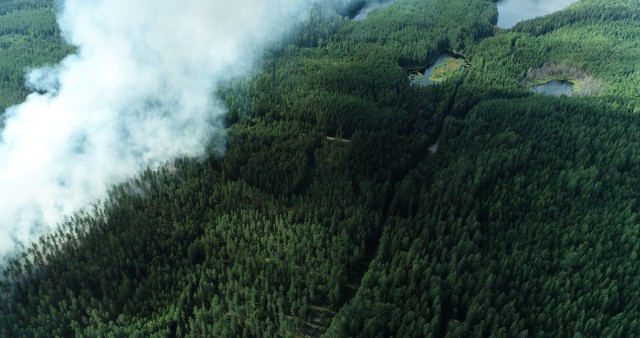

evo_11.mp4 | 15995 ms | (640, 338) | clip label=true


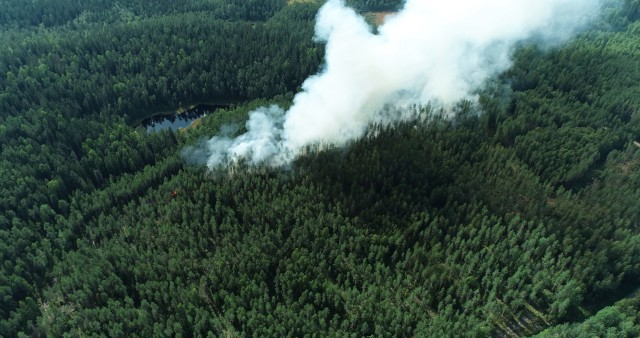

In [3]:
# A3 — Preview two representative frames and their reference metadata
for clip, rows in frames.groupby('source_clip', sort=True):
    row = rows.sort_values('timestamp_ms').iloc[len(rows) // 2]
    print(f'{clip} | {row.timestamp_ms} ms | {row.decoded_size} | clip label={row.has_smoke}')
    payload = archives.get(row.prepared_image)
    if payload and row.image_format == 'JPEG':
        with Image.open(io.BytesIO(payload)) as image:
            display(image.copy())

## A3 — Manual review notes

- At 13,993 ms, the `evo_10.mp4` preview shows a visible plume entering from the left. The sampled JPEG opens at 640 × 338 and shows no obvious decoding corruption. Keep the image for the preparation audit.
- At 15,995 ms, the `evo_11.mp4` preview shows a visible plume across the upper half. Forest and water remain distinguishable at the prepared resolution. Keep the image for the audit and treat smoke visibility at other timestamps as unverified.

| Dimension | Observation and evidence | Decision |
| --- | --- | --- |
| Completeness | The inventory accounts for all 32 expected images and joins every row to an archive member. Both clips have positive smoke labels. | Accept for pipeline quality review. Review class coverage before detector evaluation. |
| Consistency | Sample previews come from different clips and share the configured 640 × 338 output size. | Accept the sampled export format. |
| Accuracy | The source label applies to the whole clip. The two reviewed stills show visible plumes. Clip labels alone cannot establish frame-level truth at the other timestamps. | Review against timestamped ground truth before using these records as frame labels. |
| Timeliness | The pipeline manifest records its version and run time. The source inventory records the dataset release. | N.V. for whether a newer official annotation revision supersedes the reviewed labels. Compare the official release before a new evaluation. |
| Uniqueness | The inventory finds unique clip/frame keys. The pictures come from sequential samples within two clips. | Review visual near duplicates and split by clip in Part B. |

The hard judgment is whether faint smoke is visible in a particular frame. A readable image and correctly joined clip label cannot resolve that distinction. Use visual review and frame or event annotations to assess label accuracy.

In [4]:
# A4 — Evaluate explicit rules and run their Pandera schema in Colab
import math

def valid_timestamp(row):
    info = clips.get(row.source_clip)
    if not info or pd.isna(row.source_frame_index) or pd.isna(row.timestamp_ms):
        return False
    idx, ts = row.source_frame_index, row.timestamp_ms
    return (math.isfinite(idx) and float(idx).is_integer() and 0 <= idx < info['frame_count']
            and math.isfinite(ts) and 0 <= ts < info['duration_seconds'] * 1000
            and abs(ts - idx / info['fps'] * 1000) <= 1)

def valid_dimensions(row):
    if row.decoded_size is None or pd.isna(row.prepared_width) or pd.isna(row.prepared_height):
        return False
    dims = (row.prepared_width, row.prepared_height)
    return row.image_format == 'JPEG' and row.decoded_size == dims and 0 < min(dims) and max(dims) <= manifest['configuration']['max_edge']

def matches_source(row):
    if pd.isna(row.source_clip) or pd.isna(row.timestamp_ms) or pd.isna(row.source_frame_index):
        return False
    stem = Path(row.source_clip).stem
    expected = f'{prefix}{stem}/{stem}_t{int(row.timestamp_ms):06d}_f{int(row.source_frame_index):06d}.jpg'
    return row.prepared_image == expected and archive_names.get(expected) == f'{stem}_frames.zip'

rules = pd.DataFrame({
    'clip_label_matches': [
        clip in clips and isinstance(label, str)
        and label == str(clips[clip]['has_smoke']).lower()
        for clip, label in zip(frames['source_clip'], frames['has_smoke'])
    ],
    'member_present': frames['member_present'],
    'archive_matches_source_frame': frames.apply(matches_source, axis=1),
    'timestamp_matches_frame': frames.apply(valid_timestamp, axis=1),
    'jpeg_dimensions_match': frames.apply(valid_dimensions, axis=1),
    'unique_clip_frame_key': ~frames['duplicate_key'],
}, index=frames.index).astype(bool)

import pandera.pandas as pa
schema = pa.DataFrameSchema({
    name: pa.Column(bool, checks=pa.Check.eq(True), nullable=False) for name in rules.columns
})
schema_errors = None
try:
    schema.validate(rules, lazy=True)
    print(f'Pandera schema: PASS ({len(rules)} frames, {len(rules.columns)} rules)')
except pa.errors.SchemaErrors as exc:
    schema_errors = exc
    print(exc.failure_cases.to_string(index=False))

failure_rows = []
for rule in rules:
    for idx in rules.index[~rules[rule]]:
        row = frames.loc[idx]
        failure_rows.append({'rule': rule, 'source_clip': row.source_clip,
                             'source_frame_index': row.source_frame_index,
                             'prepared_image': row.prepared_image, 'decision': 'Hold and review'})
for path in sorted(extra):
    failure_rows.append({'rule': 'unindexed_archive_member', 'prepared_image': path,
                         'decision': 'Hold and review'})
failures = pd.DataFrame(failure_rows, columns=['rule','source_clip','source_frame_index','prepared_image','decision'])
out = root / 'docs' / 'week4_validation_failures.csv'
out.parent.mkdir(parents=True, exist_ok=True)
failures.to_csv(out, index=False)
print('Failures by rule:', {key: int(value) for key, value in (~rules).sum().items()})
print('Total failures including unindexed images:', len(failures))
print('Evidence file:', out.relative_to(root))
if schema_errors is not None and failures.empty:
    raise schema_errors

Pandera schema: PASS (32 frames, 6 rules)
Failures by rule: {'clip_label_matches': 0, 'member_present': 0, 'archive_matches_source_frame': 0, 'timestamp_matches_frame': 0, 'jpeg_dimensions_match': 0, 'unique_clip_frame_key': 0}
Total failures including unindexed images: 0
Evidence file: docs\week4_validation_failures.csv


### A4 rules, results and actions

| Rule | Threshold and reason | Failures | Action |
| --- | --- | ---: | --- |
| Image lineage | Archive, clip directory, filename timestamp and frame index match the CSV row. This detects swapped image references. | 0 | Hard fail. Reconcile with the Week 3 export. |
| Clip and label | Clip exists in the run manifest and its binary label matches. This catches incomplete or inconsistent joins. | 0 | Hard fail. Hold and recheck source annotations. |
| Archive membership | Every row has its exact image. The archive inventory also checks for images without rows. | 0 | Hard fail. Reconcile ZIP and CSV. |
| Timestamp | Frame index and timestamp fall within source bounds. A 1 ms tolerance accounts for rounding when deriving time from FPS. | 0 | Hard fail. Recompute from the source. |
| JPEG and dimensions | Readable JPEG with dimensions matching the index and longest edge at most 640 px, per the saved configuration. | 0 | Hard fail. Regenerate the image. |
| Uniqueness | Each clip/frame-index pair appears once. | 0 | Hard fail. Reconcile repeated keys. |


In [5]:
# A5 — Flag distinct review cases from the audited handoff
first_clip = frames[frames['source_clip'].eq('evo_10.mp4')].sort_values('timestamp_ms')
first_two = first_clip.iloc[:2]
label_counts = frames.drop_duplicates('source_clip')['has_smoke'].value_counts().to_dict()
warnings = []
if not {'true', 'false'}.issubset(label_counts):
    warnings.append(('class_coverage', f'Clip-level label counts: {label_counts}'))
if 'event_start_ms' not in frames or 'event_end_ms' not in frames:
    warnings.append(('label_granularity', 'Frame index contains clip labels and no annotated event intervals.'))
if len(first_two) == 2 and first_two['timestamp_ms'].diff().iloc[-1] <= 2100:
    warnings.append(('temporal_dependence', f"evo_10.mp4 frame indices {first_two['source_frame_index'].tolist()} "
                     f"at {first_two['timestamp_ms'].tolist()} ms come from the same clip."))
for rule, evidence in warnings:
    print(f'{rule}: {evidence}')
print(f'Review warnings: {len(warnings)} | Structural failures: {len(failures)}')

class_coverage: Clip-level label counts: {'true': 2}
label_granularity: Frame index contains clip labels and no annotated event intervals.
temporal_dependence: evo_10.mp4 frame indices [0, 96] at [0, 2002] ms come from the same clip.
Review warnings: 3 | Structural failures: 0


## A5 — Triage decisions

| Warning triggered | Evidence checked | Interpretation | Decision and reason |
| --- | --- | --- | --- |
| Class coverage lacks negative clips | Clip-level label counts: 2 positive, 0 negative. Counts use clips as the unit. | Valid exception in this two-clip preparation sample. | Retain both clips for preparation review. Add reviewed negative clips before estimating false alarms. |
| Label granularity lacks event intervals | Frame-index columns and Week 3 inventory. The two reviewed stills show plumes and the CSV records only the clip-level reference. | Frame-by-frame and event timing accuracy remain unresolved. | Retain the clip labels and review further with timestamped annotations before scoring event recall or delay. |
| Temporal dependence between nearby frames | The first two indexed samples of `evo_10.mp4` are frames 0 and 96 at 0 and 2,002 ms. | Valid sequential samples. Their visual similarity is unresolved. | Retain both for the audit. Group by source clip in evaluation splits and check near duplicates in Part B. |

The three warnings are review evidence. The validation failures CSV records zero structural failures for the audited handoff.

## Execution evidence

The saved A4 output records the Pandera result for this notebook run. A5 records review warnings separately from structural rule failures.

# Part B — Duplicates, coverage, bias, and governance

This review uses the Part A video handoff. The cleaned frame index in CSV serves the existing video workflow, and the JSONL export records the source observations for every retained image. The index and JSONL both reference the verified Week 3 archives. B1 also saves the handout's JSONL and PKL files. Each record describes a frame by source and timestamp, with the image reference and clip-level label in metadata.

In [6]:
# B1 — Exact decoded-pixel duplicates and provenance
from collections import defaultdict

if not failures.empty:
    raise ValueError("Resolve the Part A structural failures before exporting a cleaned index.")

observations = frames.sort_values(['source_clip', 'source_frame_index']).reset_index(drop=True)
groups = defaultdict(list)
for row in observations.itertuples(index=False):
    with Image.open(io.BytesIO(archives[row.prepared_image])) as image:
        rgb = image.convert('RGB')
        header = f'RGB:{rgb.width}x{rgb.height}:'.encode('ascii')
        fingerprint = hashlib.sha256(header + rgb.tobytes()).hexdigest()
    groups[fingerprint].append(row)

retained = []
duplicates = []
for fingerprint, group in groups.items():
    first = group[0]
    source_refs = [
        {'source_clip': row.source_clip, 'source_frame_index': int(row.source_frame_index),
         'timestamp_ms': int(row.timestamp_ms), 'prepared_image': row.prepared_image,
         'has_smoke': row.has_smoke}
        for row in group
    ]
    label_conflict = len({row.has_smoke for row in group}) > 1
    # Preserve all rows in a conflicting group until the labels can be reviewed.
    chosen = group if label_conflict else [first]
    for row in chosen:
        retained.append({
            'image_sha256_rgb': fingerprint, 'source_clip': row.source_clip,
            'source_frame_index': int(row.source_frame_index), 'timestamp_ms': int(row.timestamp_ms),
            'prepared_image': row.prepared_image, 'has_smoke': row.has_smoke,
            'prepared_width': int(row.prepared_width), 'prepared_height': int(row.prepared_height),
            'source_width': int(row.source_width), 'source_height': int(row.source_height),
            'sampling_interval_seconds': float(row.sampling_interval_seconds),
            'max_edge': int(row.max_edge), 'source_observations': source_refs,
            'review_status': 'label_conflict' if label_conflict else 'retained',
        })
    for row in group[1:]:
        duplicates.append({
            'image_sha256_rgb': fingerprint, 'first_clip': first.source_clip,
            'first_frame_index': first.source_frame_index, 'first_timestamp_ms': first.timestamp_ms,
            'first_image': first.prepared_image, 'duplicate_clip': row.source_clip,
            'duplicate_frame_index': row.source_frame_index, 'duplicate_timestamp_ms': row.timestamp_ms,
            'duplicate_image': row.prepared_image,
            'decision': 'retain both for label review' if label_conflict else 'retain first and preserve both source references',
        })

clean_dir = root / 'data' / 'quality_v1' / 'video'
clean_dir.mkdir(parents=True, exist_ok=True)
retained.sort(key=lambda row: (row['source_clip'], row['source_frame_index']))
jsonl_path = clean_dir / 'prepared_frames_clean.jsonl'
jsonl_path.write_text(''.join(json.dumps(row) + '\n' for row in retained), encoding='utf-8')
csv_path = clean_dir / 'frame_manifest_clean.csv'
pd.DataFrame([{k: v for k, v in row.items() if k != 'source_observations'} for row in retained]).to_csv(csv_path, index=False)
review_columns = ['image_sha256_rgb', 'first_clip', 'first_frame_index', 'first_timestamp_ms',
                  'first_image', 'duplicate_clip', 'duplicate_frame_index', 'duplicate_timestamp_ms',
                  'duplicate_image', 'decision']
pd.DataFrame(duplicates, columns=review_columns).to_csv(root / 'docs/week4_duplicate_review.csv', index=False)
print(f'Before: {len(observations)} | After: {len(retained)} | Exact duplicate observations: {len(duplicates)}')
print('Clean exports:', jsonl_path.relative_to(root), 'and', csv_path.relative_to(root))


# Handout-compatible records. The text identifies a frame and makes no visual claim.
import pickle
from types import SimpleNamespace

course_records = []
for i, row in enumerate(retained):
    metadata = dict(row, source=row['source_clip'])
    text = f"Frame {row['source_frame_index']} from {row['source_clip']} at {row['timestamp_ms']} ms."
    course_records.append({'chunk_id': i, 'text': text, 'metadata': metadata})

course_jsonl = root / 'data/prepared_chunks_clean.jsonl'
course_pkl = root / 'data/chunks_clean.pkl'
course_jsonl.write_text(''.join(json.dumps(item) + '\n' for item in course_records), encoding='utf-8')
with course_pkl.open('wb') as stream:
    pickle.dump([SimpleNamespace(page_content=item['text'], metadata=item['metadata'])
                 for item in course_records], stream, protocol=4)

with course_pkl.open('rb') as stream:
    loaded = pickle.load(stream)  # Reload the file just written by this cell.
records = [json.loads(line) for line in course_jsonl.read_text(encoding='utf-8').splitlines()]
assert records == course_records
assert records == [dict(chunk_id=i, text=item.page_content, metadata=item.metadata)
                   for i, item in enumerate(loaded)]
print(f'Course JSONL and PKL reloaded: {len(records)} matching records, including provenance.')


Before: 32 | After: 32 | Exact duplicate observations: 0
Clean exports: data\quality_v1\video\prepared_frames_clean.jsonl and data\quality_v1\video\frame_manifest_clean.csv
Course JSONL and PKL reloaded: 32 matching records, including provenance.


**B1 interpretation.** The hash covers decoded RGB pixels and dimensions. It detects exact pixel equality even when JPEG encoding details differ. Near matches, successive views and incorrect annotations require separate review. Provenance records point to each original clip, frame index, timestamp and archive image.

## B2 — Define adequate coverage before counting

| Required area | Why it matters | Evidence needed |
| --- | --- | --- |
| Positive and negative reference clips | FR-03 and EC-02 need both classes to evaluate missed detections and false alarms on meaningful cases. | Independently reviewed clips with positive and negative labels and a documented sampling plan. |
| Event timing | FR-03 and EC-02 require timestamps to assess event recall and delay. | Reviewed event start times or intervals linked to clip IDs. |
| Capture conditions | RAI-04 and EC-04 require coverage claims tied to documented conditions. | Per-clip data for relevant capture settings, visibility and other evaluation conditions. |
| Clip provenance | FR-01 and EC-04 require traceable inputs. | Clip identifier and paths linked to reviewed reference labels and the Week 3 source inventory. |

Frame counts show the size of each processed sample. Coverage of classes is measured at the clip level using the actual `has_smoke` label. Clip IDs identify inputs. They serve as neither scene categories nor independent fire-event identifiers.

             retained_frames  percent
source_clip                          
evo_10.mp4                15    46.88
evo_11.mp4                17    53.12
Reference label counts by clip:
has_smoke
smoke-positive    2
smoke-negative    0
unresolved        0
Event interval fields present: False
Per-clip scene category: unknown in the prepared index.


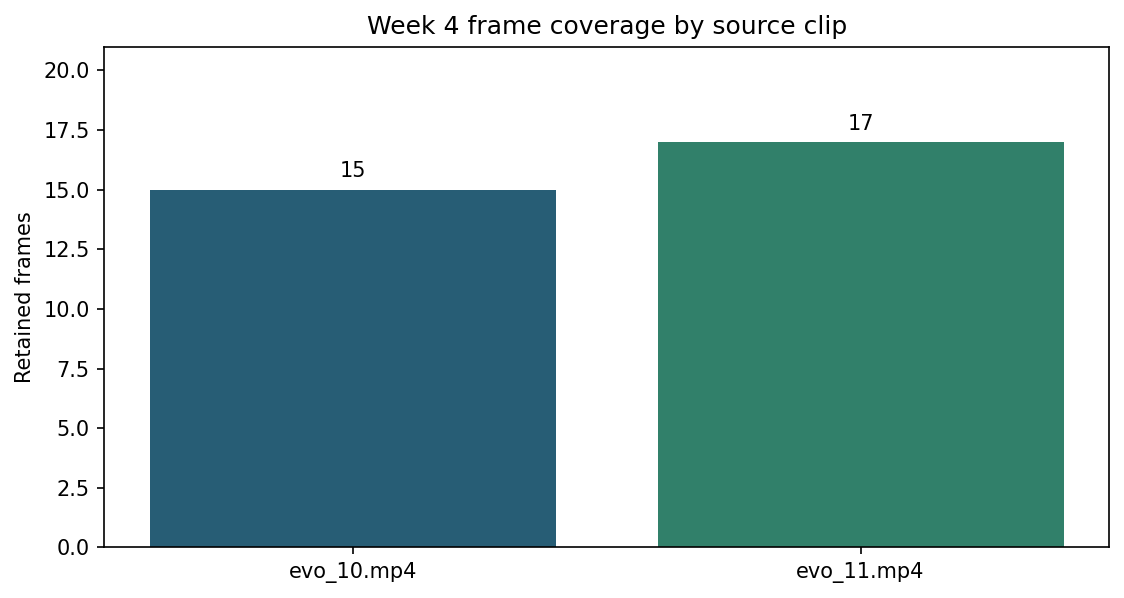

In [7]:
# B2 — Measure coverage and save the source chart
import matplotlib.pyplot as plt

clean = pd.DataFrame(retained)
source_coverage = clean.groupby('source_clip').size().rename('retained_frames').to_frame()
source_coverage['percent'] = (100 * source_coverage['retained_frames'] / len(clean)).round(2)
print(source_coverage.to_string())
class_by_clip = observations.groupby('source_clip')['has_smoke'].agg(lambda values: set(values))
class_counts = class_by_clip.map(
    lambda labels: 'smoke-positive' if labels == {'true'} else 'smoke-negative' if labels == {'false'} else 'unresolved'
).value_counts().reindex(['smoke-positive', 'smoke-negative', 'unresolved'], fill_value=0)
print('Reference label counts by clip:')
print(class_counts.to_string())
print('Event interval fields present:', all(name in observations for name in ('event_start_ms', 'event_end_ms')))
print('Per-clip scene category: unknown in the prepared index.')

fig, ax = plt.subplots(figsize=(7.6, 4.1))
bars = ax.bar(source_coverage.index, source_coverage['retained_frames'], color=['#275D75', '#31806A'])
ax.bar_label(bars, padding=4)
ax.set_ylim(0, max(source_coverage['retained_frames']) + 4)
ax.set_ylabel('Retained frames')
ax.set_title('Week 4 frame coverage by source clip')
fig.tight_layout()
chart_path = root / 'docs/week4_coverage_by_source.png'
fig.savefig(chart_path, dpi=150, bbox_inches='tight')
plt.close(fig)

display(Image.open(chart_path))


**B2 findings.** The cleaned index retains 15 frames from `evo_10.mp4` and 17 from `evo_11.mp4`. Both clips are smoke-positive. Negative clips are a genuine gap for false-alarm evaluation. Event intervals are a separate gap for detection delay and event recall. The two-frame difference is a quantity difference. Condition coverage remains undetermined because the prepared index has no per-clip scene categories.

## B3 — Bias risks and downstream effects

For this project, the analogous downstream stages are clip selection, detector inference, event matching and the generated evaluation report.

| Risk | Evidence and origin | Propagation and affected cases | Intervention | Planned system test |
| --- | --- | --- | --- | --- |
| Historical coverage risk | The source inventory describes a fixed collection of Finnish prescribed-burn UAV footage. The extent of temporal or operational changes since capture is unknown. | Source context limits the prepared footage. An evaluation report could overstate applicability to newer cameras, newer capture conditions or uncontrolled incidents. | Record capture period where documented, dataset version and camera/operational context. Add independent clips from other periods and conditions. | Compare performance on held-out sources and capture periods with documented differences. |
| Representation bias risk | The selected sample has two smoke-positive clips and zero negative clips. The gap originates in clip selection and persists after frame sampling. | A detector could trigger on smoke-like negatives such as fog and still appear reliable in a report based only on this subset. | Include reviewed negatives and smoke-like confounders. Split by source clip or incident where incident IDs are available. | Evaluate false alarms per evaluated duration on held-out negatives and report each coverage category supported by the data. |
| Measurement bias risk | Labels describe entire clips and the preparation samples every two seconds. A positive clip label may cover frames before the plume appears. Sparse sampling can skip brief events. | Applying the clip label to every frame can miscount misses. Sampling and absent event boundaries can distort delay estimates and the final report. | Preserve the label as clip metadata, obtain reviewed event intervals and compare denser sampling with the current setting. Mark unsupported metrics unavailable. | Use held-out clips with reviewed timestamps to test event recall and delay at multiple sampling intervals. |

These are dataset risks. Topic 8 evaluation will require detector outputs and held-out references to measure their actual effects.

## B4 — Responsible data and governance

| Review question | Evidence | Status | Action and owner |
| --- | --- | --- | --- |
| Can the source, version and provenance be traced? | Week 3 inventory identifies the Boreal Forest Fire dataset, Subset B, and its recorded release. The run manifest provides file hashes and the clean index preserves clip and frame references. | OK for the audited handoff. | Student maintainer records version, source and new hashes on each import. |
| Are use and redistribution rights appropriate? | The Week 3 inventory records CC BY 4.0 for the source and links to its publisher record. Prepared images were sampled, resized and re-encoded. | Audit proceeds under the documented license. Verify asset terms again before a new release or source addition. | Student maintainer retains attribution, the license link and a description of the transformations. Holds assets with uncertain rights before public release. |
| Does unnecessary personal or sensitive data appear? | The two manually reviewed frames show aerial forest footage. A complete people, identifier and location-metadata review has not been performed. | Unknown for the full set. | Student maintainer reviews the retained exports and metadata before expanding publication. Quarantine frames or metadata with unnecessary identifying details. |
| Is collection basis or consent documented where applicable? | The project reuses research footage. The review has no evidence about individual consent for any identifiable person who might appear. | N/A to new collection for this run. Verify if identifying material is found. | Student maintainer holds affected clips while checking the source terms and appropriate basis. |
| Who handles updates, superseded data and removal? | The source version and hashes are recorded. The project needs an operational owner for future refreshes. | Maintenance procedure defined for future runs. | Student maintainer checks for source corrections before evaluation, records the replacement version and date, regenerates affected exports, retires superseded outputs from active use and handles removal requests according to source terms and course requirements. |
